# KuaiRand data exploration

## Loading data

In [ ]:
from pathlib import Path

cartella = Path("KuaiRand-1K")
archivio = Path("KuaiRand-1K.tar.gz")

if cartella.exists():
    print("KuaiRand-1K già estratta, salto l'estrazione.")
else:
    if not archivio.exists():
        print("Archivio non trovato, lo scarico...")
        !wget https://zenodo.org/records/10439422/files/KuaiRand-1K.tar.gz
    else:
        print("Archivio già presente, salto il download.")
    !tar -xzvf KuaiRand-1K.tar.gz

KuaiRand-1K già estratta, salto l'estrazione.


In [2]:
from IPython.display import Markdown
Markdown(open("KuaiRand-1K/README.md", encoding="utf-8").read())

# KuaiRand: An Unbiased Sequential Recommendation Dataset with Randomly Exposed Videos 

[![LICENSE](https://img.shields.io/badge/license-CC%20BY--SA%204.0-green)](https://github.com/chongminggao/KuaiRand/blob/main/LICENSE)

*KuaiRand* is an unbiased sequential recommendation dataset collected from the recommendation logs of the video-sharing mobile app, [Kuaishou (快手)](https://www.kuaishou.com/cn).  **It is the first recommendation dataset with millions of  intervened interactions of randomly exposed items inserted in the standard recommendation feeds!** 

## Overview:

The following figure gives an example of the dataset. It illustrates a user interaction sequence along with the user's rich feedback signals.

![kuaidata](./figs/KuaiRand.png)

These feedback signals are collected from the two main user interfaces (UI) in Kuaishou APP shown as follows:

<img src="figs/kuaishou-app.png" alt="kuaishou-app" style="display: block;margin: auto;zoom:35%;" />

In the random exposure stage, each recommended video in the dataset has an equal probability being replaced by a random video sampled from an item pools. About $0.37\%$ Interactions are replaced in the final results. 

#### Advantages:

Compared with other datasets with random exposure, KuaiRand has the following advantages:

- ✅ It is the first sequential recommendation dataset with millions of  intervened interactions of randomly exposed items inserted in the standard recommendation feeds.
- ✅ It has the most comprehensive side information including explicit user IDs, interaction timestamps, and rich features for users and items.
- ✅ It has 15 policies with each catered for a special recommendation scenario in Kuaishou App.
- ✅ We introduce 12 feedback signals (e.g., click, like, and view time) for each interaction to describe the user's comprehensive feedback.
- ✅ Each user has thousands of historical interactions on average.
- ✅ It has three versions to support various research directions in recommendation.

----

## Three Versions and Suggestions:

We release three versions of KuaiRand for different usage:

- **KuaiRand-27K (23GB logs +23GB features):** the complete KuaiRand dataset that has over 27K users and 32 millions videos.
- **KuaiRand-1K  (829MB logs + 3.5GB features):** randomly sample 1,000 users from *KuaiRand-27K*, then remove all irrelevant videos. There are 4 millions videos rest. 
- **KuaiRand-Pure  (184MB logs + 10MB features):** only keeps the logs for the 7582 videos in the candidate pool. 

The *user_id* and *video_id* are re-indexed. A visualization of their ID spaces is shown as follows.

![kuaidata](./figs/three-version.png)

##### The basic statistics of the three versions are summarized as follows:

| Dataset          | Collection Policy  | #Users |   #Items   | #Interactions | #User features | #Item features | Feedback      | Timestamp |
| ---------------- | :----------------: | :----: | :--------: | :-----------: | :--------------: | :--------------: | :-------------: | :---------: |
| **KuaiRand-27K** |    15 policies     | 27,285 | 32,038,725 |  322,278,385  | 30             | 62            | 12 signals    | ✔️ |
|                  |   Random policy    | 27,285 |   7,583    |   1,186,059   | 30             | 62            | 12 signals    | 	✔️ |
| **KuaiRand-1K**  |    15 policies     | 1,000  | 4,369,953  |  11,713,045   | 30             | 62            | 12 signals    | ✔️ |
|                  |   Random policy    | 1,000  |   7,388    |    43,028     | 30             | 62            | 12 signals    | ✔️ |
| **KuaiRand-Pure**  |    15 policies     | 27,285 | 7,551 | 1,436,609 | 30             | 62            | 12 signals    | ✔️ |
|                  |   Random policy    | 27,285 | 7,583 | 1,186,059 | 30             | 62            | 12 signals    | ✔️ |


### Which version should I use?

- ##### Reasons to use *KuaiRand-27K* or *KuaiRand-1K*:

  - Your research needs rigorous sequential logs, such as off-policy evaluation (OPE), Reinforcement learning (RL), or long sequential recommendation.

- ##### Reasons to use *KuaiRand-Pure*:

  - The sequential information is not necessary in your research OR If you are OK with the incomplete sequential logs. For example, if you are studying debiasing in collaborative filtering models or multi-task modeling in recommendation.
  - If your model can only run with small-size data.


---


## Download the data

We provides several options to download the datasets:

#### Option 1. Download via the "wget" command.

##### KuaiRand-27K (compressed size: 9.21GB; uncompressed size: 46GB)

```shell
wget https://chongming.myds.me:61364/data/KuaiRand-27K.tar.gz --no-check-certificate
tar -zxvf KuaiRand-27K.tar.gz
```

##### KuaiRand-1K (compressed size: 1GB; uncompressed size: 4.3GB)


```shell
wget https://chongming.myds.me:61364/data/KuaiRand-1K.tar.gz --no-check-certificate
tar -zxvf KuaiRand-1K.tar.gz
```

##### KuaiRand-Pure (compressed size: 45.2MB; uncompressed size: 194MB)

```shell
wget https://chongming.myds.me:61364/data/KuaiRand-Pure.tar.gz --no-check-certificate
tar -zxvf KuaiRand-Pure.tar.gz
```

#### Option 2. Download manually through the following links:

  - Optional link 1: [Google Drive](https://drive.google.com/drive/folders/1BHcv3bgoXOOm2rjmgBYtpIqry883gwj3?usp=sharing)

  - Optional link 2: [USTC Drive (中科大)](https://rec.ustc.edu.cn/share/e10dfc20-e657-11ec-9f09-f306a85f66ae)

The script `loaddata.py` provides a simple way to load the data via Pandas in Python.

---

## Data Descriptions

The file structure of the three datasets are listed as follows:

##### KuaiRand-27K (46GB)

  ```shell
  KuaiRand-27K
  ├── data (46GB)
  │   ├── log_random_4_22_to_5_08_27k.csv (83MB)
  │   ├── log_standard_4_08_to_4_21_27k_part1.csv (4.8GB)
  │   ├── log_standard_4_08_to_4_21_27k_part2.csv (4.8GB)
  │   ├── log_standard_4_22_to_5_08_27k_part1.csv (6.6GB)
  │   ├── log_standard_4_22_to_5_08_27k_part2.csv (6.6GB)
  │   ├── user_features_27k.csv (3.4MB)
  │   ├── video_features_basic_27k.csv (2.6GB)
  │   ├── video_features_statistic_27k_part1.csv (6.7GB)
  │   ├── video_features_statistic_27k_part2.csv (6.7GB)
  │   └── video_features_statistic_27k_part3.csv (6.7GB)
  └── load_data_27k.py
  ```

##### KuaiRand-1K (4.3GB)

  ```shell
  KuaiRand-1K
  ├── data (4.3GB)
  │   ├── log_random_4_22_to_5_08_1k.csv (2.9MB)
  │   ├── log_standard_4_08_to_4_21_1k.csv (368MB)
  │   ├── log_standard_4_22_to_5_08_1k.csv (481MB)
  │   ├── user_features_1k.csv (132KB)
  │   ├── video_features_basic_1k.csv (368MB)
  │   └── video_features_statistic_1k.csv (3.1GB)
  └── load_data_1k.py
  ```

##### KuaiRand-Pure (194MB)

  ```shell
  KuaiRand-Pure
  ├── data (194MB)
  │   ├── log_random_4_22_to_5_08_pure.csv (83MB)
  │   ├── log_standard_4_08_to_4_21_pure.csv (80MB)
  │   ├── log_standard_4_22_to_5_08_pure.csv (21MB)
  │   ├── user_features_pure.csv (3.4MB)
  │   ├── video_features_basic_pure.csv (612KB)
  │   └── video_features_statistic_pure.csv (6.3MB)
  └── load_data_pure.py
  ```

---

####  1️⃣ Descriptions of the fields in `log_xxx.csv` 

There are three log files:

- `log_random_4_22_to_5_08.csv` contains all interactions resulted from random intervention.
- `log_standard_4_22_to_5_08.csv` contains all interactions of standard recommendation.
- `log_standard_4_08_to_4_21.csv` contains all interactions of standard recommendation for the same users in the previous two weeks (2022.04.08 ~ 2022.04.21).

| Field Name:       | Description                                                                                                                    | Type    | Example   |
| ----------------- | ------------------------------------------------------------                                                                   | ------- | --------- |
| user_id           | The ID of the video.                                                                                                           | int64   |        17387|
| video_id          | The ID of the video.                                                                                                           | int64   |      1123453|
| date              | The date of this interaction                                                                                                   | int64   |     20220421|
| hourmin           | The time of this interaction (format: HHSS).                                                                                   | int64   |          400|
| time_ms           | The timestamp of this interaction in millisecond.                                                                          | int64   |1650485801301|
| is_click          | A binary feedback signal. In the two-column UI, it indicates a click; In the single-column UI, it means *valid_play*: which equals 1 when: `play_duration >= video_duration if video_duration <= 7s`, or `play_duration > 7 if video_duration > 7s`. | int64   | 1     |
| is_like           | A binary feedback signal indicating the user hit the `like` button.                                                            | int64   |            0|
| is_follow         | A binary feedback signal indicating the user hit the `follow the author` button.                                               | int64   |            0|
| is_comment        | A binary feedback signal indicating the user writed comment in the comments section of this video                              | int64   |            0|
| is_forward        | A binary feedback signal indicating the user forwarded this video.                                                             | int64   |            0|
| is_hate           | A binary feedback signal indicating the user hated this video.                                                                 | int64   |            0|
| long_view         | A binary feedback signal. It equals 1 when: `play_duration >= video_duration if video_duration <= 18s`, or `play_duration >=18 if video_duration > 18s`. | int64   |            1|
| play_time_ms      | The user's view time in millisecond.                                                                                           | int64   |       151024|
| duration_ms       | The video's duration time in millisecond.                                                                                      | int64   |       104400|
| profile_stay_time | The time that the user stayed in this author's profile.                                                                        | int64   |            0|
| comment_stay_time | The time that the user stayed in the comments section of this video                                                            | int64   |            0|
| is_profile_enter  | A binary feedback signal indicating the user enters the author profile                                                         | int64   |            0|
| is_rand           | A binary signal indicating if this video is generated by the random intervention (i.e., a random exposed video). | int64   |            0|
| tab               | indicating the scenario of this interaction, e.g., in the recommendation page or the main page of the App. In range of [0,14]. | int64   |            1|

---

####  2️⃣ Descriptions of the fields in `user_features.csv`

| Field Name:              | Description                                              | Type    | Example                   |
| ------------------------ | -------------------------------------------------------- | ------- | ------------------------- |
| user_id                  | The ID of the user.                                      | int64    |      25621    |
| user_active_degree       | In the set of {'high_active', 'full_active', 'middle_active', 'UNKNOWN'}. | str    |  "full_active"  |
| is_lowactive_period      | Is this user in its low active period | int64    |           0    |
| is_live_streamer         | Is this user a live streamer？ | int64    |    0    |
| is_video_author          | Has this user uploaded any video？ | int64    |          1    |
| follow_user_num          | The number of users that this user follows. | int64    |           5    |
| follow_user_num_range    | The range of the number of users that this user follows. In the set of {'0', '(0,10]', '(10,50]', '(100,150]', '(150,250]', '(250,500]', '(50,100]', '500+'} | str    |     "(0,10]"  |
| fans_user_num            | The number of the fans of this user. | int64    |        312    |
| fans_user_num_range      | The range of the number of fans of this user. In the set of {'0', '[1,10)', '[10,100)', '[100,1k)', '[1k,5k)',  '[5k,1w)', '[1w,10w)'} | str    |  "[100,1k)"  |
| friend_user_num          | The number of friends that this user has. | int64    |           0    |
| friend_user_num_range    | The range of the number of friends that this user has.  In the set of {'0', '[1,5)', '[5,30)', '[30,60)', '[60,120)', '[120,250)', '250+'} | str    |           "0"  |
| register_days            | The days since this user has registered. | int64    |     3624    |
| register_days_range      | The range of the registered days. In the set of {'15-30', '31-60', '61-90', '91-180', '181-365', '366-730', '730+'}. | str    |    "730+"  |
| onehot_feat0             | An encrypted feature of the user. Each value indicate the position of "1" in the one-hot vector. Range: {0,1} | int64    |          1    |
| onehot_feat1             | An encrypted feature. Range: {0, 1, ..., 6} | int64    |          2    |
| onehot_feat2             | An encrypted feature. Range: {0, 1, ..., 49} | int64    |          2    |
| onehot_feat3             | An encrypted feature. Range: {0, 1, ..., 1470} | int64    |     1153    |
| onehot_feat4             | An encrypted feature. Range: {0, 1, ..., 14} | int64    |        4    |
| onehot_feat5             | An encrypted feature. Range: {0, 1, ..., 33} | int64    |           0    |
| onehot_feat6             | An encrypted feature. Range: {0, 1, 2} | int64    |          0    |
| onehot_feat7             | An encrypted feature. Range: {0, 1, ..., 117} | int64    |         31    |
| onehot_feat8             | An encrypted feature. Range: {0, 1, ..., 453} | int64    |      354    |
| onehot_feat9             | An encrypted feature. Range: {0, 1, ..., 6} | int64    |          3    |
| onehot_feat10            | An encrypted feature. Range: {0, 1, ..., 4} | int64    |           3    |
| onehot_feat11            | An encrypted feature. Range: {0, 1, ..., 4} | int64    |          2    |
| onehot_feat12            | An encrypted feature. Range: {0, 1} | int64    |          1    |
| onehot_feat13            | An encrypted feature. Range: {0, 1} | int64    |           0    |
| onehot_feat14            | An encrypted feature. Range: {0, 1} | int64    |           0    |
| onehot_feat15            | An encrypted feature. Range: {0, 1} | int64    |           0    |
| onehot_feat16            | An encrypted feature. Range: {0, 1} | int64    |           0    |
| onehot_feat17            | An encrypted feature. Range: {0, 1} | int64    |           0    |

---

####  3️⃣ Descriptions of the fields in `video_features_basic.csv`

| Field Name:    | Description                                                  | Type  | Example       |
| -------------- | ------------------------------------------------------------ | ----- | ------------- |
| video_id       | The ID of the video.                                         | int64 | 3784          |
| author_id      | The ID of the author of this video. In the range of [0, 8839734] | int64 | 441           |
| video_type     | Type of this video (NORMAL or AD).                           | str   | "NORMAL"      |
| upload_dt      | Upload date of this video.                                   | str   | "2020-07-08"  |
| upload_type    | The upload type of this video.                               | str   | "ShortImport" |
| visible_status | The visible state of this video on the APP now.              | int   | 1             |
| video_duration | The time duration of this duration (in millisecond).         | Int64 | 17200.0       |
| server_width   | The width of this video on the server.                       | int64 | 720           |
| server_height  | The height of this video on the server.                      | int64 | 1280          |
| music_id       | Background music ID of this video.                           | int64 | 989206467     |
| music_type     | Background music type of this video.                         | int64 | 4             |
| tag            | A list of key categories (labels) of this video.             | str   | "12,65"       |

---

#### 4️⃣ Descriptions of the fields in `video_features_statistic.csv`

‼️ Different from the basic features, the statistical features are the average statistics of the video each day over the one month. For example, in the following table, the video 9288071 have 66 counts over this one month (a video can have multiple counts each day on different scenarios, e.g., on April 8, `show_cnt`=80 on the main page and `show_cnt`=65 on the recommendation page of the App)

| Field Name:              | Description                                                  | Type    | Example   |
| ------------------------ | ------------------------------------------------------------ | ------- | --------- |
| video_id                 | The ID of the video.                                         | int64   | 9288071   |
| counts                   | The number of statistics.                                    | int64   | 66        |
| show_cnt                 | The number of shows of this video **(averaged on each day and each scenario over the one month. This applies to all the following fields)** | float64 | 75.212    |
| show_user_num            | The number of users who received the recommendation of this video. | float64 | 66.985    |
| play_cnt                 | The number of plays.                                         | float64 | 9.409     |
| play_user_num            | The number of users who plays this video.                    | float64 | 8.121     |
| play_duration            | The total time duration of playing this video (in millisecond). | float64 | 93700.333 |
| complete_play_cnt        | The number of complete plays. *complete play*: finishing playing the whole video, i.e., `#(play_duration >= video_duration)`. | float64 | 0.182     |
| complete_play_user_num   | The number of users who perform the *complete play*.         | float64 | 0.182     |
| valid_play_cnt           | *valid play*: `play_duration >= video_duration if video_duration <= 7s`, or `play_duration > 7 if video_duration > 7s`. | float64 | 3.545     |
| valid_play_user_num      | The number of users who perform the *complete play*.         | float64 | 3.136     |
| long_time_play_cnt       | *long time play*: `play_duration >= video_duration if video_duration <= 18s`, or `play_duration >=18 if video_duration > 18s`. | float64 | 1.909     |
| long_time_play_user_num  | The number of users who perform the *long time play*.        | float64 | 1.848     |
| short_time_play_cnt      | *short time play*: `play_duration < min(3s, video_duration)`. | float64 | 5.015     |
| short_time_play_user_num | The number of users who perform the *short time play*.       | float64 | 4.545     |
| play_progress            | The average video playing ratio (`=play_duration/video_duration`) | float64 | 0.016     |
| comment_stay_duration    | Total time of staying in the comments section                | float64 | 2302.712  |
| like_cnt                 | Total likes                                                  | float64 | 0.303     |
| like_user_num            | The number of users who hit the "like" button.               | float64 | 0.303     |
| click_like_cnt           | The number of the "like" resulted from double click          | float64 | 0.030     |
| double_click_cnt         | The number of users who double click the video.              | float64 | 0.273     |
| cancel_like_cnt          | The number of likes that are cancelled by users.             | float64 | 0.485     |
| cancel_like_user_num     | The number of users who cancel their like.                   | float64 | 0.485     |
| comment_cnt              | The number of comments within this day.                      | float64 | 0.015     |
| comment_user_num         | The number of users who comment this video.                  | float64 | 0.015     |
| direct_comment_cnt       | The number of direct comments (depth=1).                     | float64 | 0.015     |
| reply_comment_cnt        | The number of reply comments (depth>1).                      | float64 | 0.000     |
| delete_comment_cnt       | The number of deleted comments.                              | float64 | 0.015     |
| delete_comment_user_num  | The number of users who delete their comments.               | float64 | 0.015     |
| comment_like_cnt         | The number of comment likes.                                 | float64 | 0.000     |
| comment_like_user_num    | The number of users who like the comments.                   | float64 | 0.000     |
| follow_cnt               | The number of increased follows from this video.             | float64 | 0.000     |
| follow_user_num          | The number of users who follow the author of this video due to this video. | float64 | 0.000     |
| cancel_follow_cnt        | The number of decreased follows from this video.             | float64 | 0.000     |
| cancel_follow_user_num   | The number of users who cancel their following of the author of this video due to this video. | float64 | 0.000     |
| share_cnt                | The times of successfully sharing this video.                | float64 | 0.000     |
| share_user_num           | The number of users who succeed to share this video.         | float64 | 0.000     |
| download_cnt             | The times of downloading this video.                         | float64 | 0.030     |
| download_user_num        | The number of users who download this video.                 | float64 | 0.030     |
| report_cnt               | The times of reporting this video.                           | float64 | 0.000     |
| report_user_num          | The number of users who report this video.                   | float64 | 0.000     |
| reduce_similar_cnt       | The times of reducing similar content of this video.         | float64 | 0.015     |
| reduce_similar_user_num  | The number of users who choose to reduce similar content of this video. | float64 | 0.015     |
| collect_cnt              | The times of adding this video to favorite videos.           | float64 | 0.061     |
| collect_user_num         | The number of users who add this video to their favorite videos. | float64 | 0.061     |
| cancel_collect_cnt       | The times of removing this video from favorite videos.       | float64 | 0.091     |
| cancel_collect_user_num  | The number of users who remove this video from their favorite videos | float64 | 0.091     |
| direct_comment_user_num  | The number of users who write comments directly under this video (level=1). | float64 | 0.015     |
| reply_comment_user_num   | The number of users who reply the existing comments (level>1). | float64 | 0.000     |
| share_all_cnt            | The times of sharing this video (no need to be successful).  | float64 | 0.015     |
| share_all_user_num       | The number of users who share this video (no need to be successful). | float64 | 0.015     |
| outsite_share_all_cnt    | The times of sharing this video outside Kuaishou App.        | float64 | 0.000     |



In [3]:
from pathlib import Path
import tarfile
import urllib.request
import sys

# Unica variabile da cambiare. Colab: "."  |  In locale: una cartella fuori da OneDrive, es. Path(r"C:\dati")
ROOT = Path(".")
DATA_DIR = Path.joinpath(ROOT,"KuaiRand-1K","data") 
URL = "https://zenodo.org/records/10439422/files/KuaiRand-1K.tar.gz"

if not DATA_DIR.exists():
    archive = ROOT / "KuaiRand-1K.tar.gz"
    if not archive.exists():
        print("Scarico l'archivio (~1,1 GB)...")
        urllib.request.urlretrieve(URL, archive)
    print("Estraggo...")
    with tarfile.open(archive, "r:gz") as tf:
        tf.extractall(ROOT, filter="data")

for f in sorted(DATA_DIR.iterdir()):
    print(f"{f.name:40s} {f.stat().st_size / 1e6:8.0f} MB")

log_random_4_22_to_5_08_1k.csv                  3 MB
log_standard_4_08_to_4_21_1k.csv              374 MB
log_standard_4_22_to_5_08_1k.csv              492 MB
user_features_1k.csv                            0 MB
video_features_basic_1k.csv                   377 MB
video_features_statistic_1k.csv              3371 MB


In [4]:
import pandas as pd
from matplotlib import pyplot as plt

## Data exploration on the datasets
### Log standard dataset
This dataset has millions of rows so it's split in 2. Now we start by analyzing the first one.

One row is one video shown to the user

In [5]:
PATH_LOG_1 = Path.joinpath(DATA_DIR,"log_standard_4_08_to_4_21_1k.csv")
PATH_LOG_2 = Path.joinpath(DATA_DIR,"log_standard_4_22_to_5_08_1k.csv")

df_log = pd.concat([pd.read_csv(PATH_LOG_1),pd.read_csv(PATH_LOG_2)])

In [6]:
df_log.info(memory_usage="deep", show_counts=True)


<class 'pandas.core.frame.DataFrame'>
Index: 11713045 entries, 0 to 6657060
Data columns (total 19 columns):
 #   Column             Non-Null Count     Dtype
---  ------             --------------     -----
 0   user_id            11713045 non-null  int64
 1   video_id           11713045 non-null  int64
 2   date               11713045 non-null  int64
 3   hourmin            11713045 non-null  int64
 4   time_ms            11713045 non-null  int64
 5   is_click           11713045 non-null  int64
 6   is_like            11713045 non-null  int64
 7   is_follow          11713045 non-null  int64
 8   is_comment         11713045 non-null  int64
 9   is_forward         11713045 non-null  int64
 10  is_hate            11713045 non-null  int64
 11  long_view          11713045 non-null  int64
 12  play_time_ms       11713045 non-null  int64
 13  duration_ms        11713045 non-null  int64
 14  profile_stay_time  11713045 non-null  int64
 15  comment_stay_time  11713045 non-null  int64
 16  is_p

In [7]:
# è tutto int64 il mio pc è piantato quindi restringo i tipi delle celle che non necessitano così tanto spazio
# e ricarico il dataframe

FLAGS = [s for s in df_log.columns if s.startswith("is") or s == "long_view"]
TIME_COLS = ["play_time_ms", "duration_ms", "profile_stay_time", "comment_stay_time"]

LOG_DTYPES = {
    "user_id": "int16", "video_id": "int32", "date": "int32", "hourmin": "int16",
    "time_ms": "int64", "tab": "int8",
    **{c: "int8" for c in FLAGS},
    **{c: "int64" for c in TIME_COLS},   # nessun massimo documentato: leggo largo, poi restringo
}

def load_log(path):
    df = pd.read_csv(path, dtype=LOG_DTYPES)
    for c in TIME_COLS:
        df[c] = pd.to_numeric(df[c], downcast="integer")  # tipo più piccolo che contiene tutti i valori
    return df

df_log = pd.concat([load_log(PATH_LOG_1),load_log(PATH_LOG_2)])
print(f"Memoria: {df_log.memory_usage(deep=True).sum() / 2**20:.0f} MiB")

Memoria: 603 MiB


In [8]:
df_log.info(memory_usage="deep", show_counts=True)


<class 'pandas.core.frame.DataFrame'>
Index: 11713045 entries, 0 to 6657060
Data columns (total 19 columns):
 #   Column             Non-Null Count     Dtype
---  ------             --------------     -----
 0   user_id            11713045 non-null  int16
 1   video_id           11713045 non-null  int32
 2   date               11713045 non-null  int32
 3   hourmin            11713045 non-null  int16
 4   time_ms            11713045 non-null  int64
 5   is_click           11713045 non-null  int8 
 6   is_like            11713045 non-null  int8 
 7   is_follow          11713045 non-null  int8 
 8   is_comment         11713045 non-null  int8 
 9   is_forward         11713045 non-null  int8 
 10  is_hate            11713045 non-null  int8 
 11  long_view          11713045 non-null  int8 
 12  play_time_ms       11713045 non-null  int32
 13  duration_ms        11713045 non-null  int32
 14  profile_stay_time  11713045 non-null  int32
 15  comment_stay_time  11713045 non-null  int32
 16  is_p

In [13]:
pd.set_option("display.float_format", "{:,.2f}".format)
df_log.describe()

,user_id,video_id,date,hourmin,time_ms,is_click,is_like,is_follow,is_comment,is_forward,is_hate,long_view,play_time_ms,duration_ms,profile_stay_time,comment_stay_time,is_profile_enter,is_rand,tab
count,"11,713,045.00","11,713,045.00","11,713,045.00","11,713,045.00","11,713,045.00","11,713,045.00","11,713,045.00","11,713,045.00","11,713,045.00","11,713,045.00","11,713,045.00","11,713,045.00","11,713,045.00","11,713,045.00","11,713,045.00","11,713,045.00","11,713,045.00","11,713,045.00","11,713,045.00"
mean,509.24,"2,182,057.10","20,220,443.09","1,427.37","1,650,727,874,486.51",0.38,0.02,0.00,0.00,0.00,0.00,0.26,"14,790.27","72,180.92",6.82,491.49,0.02,0.00,1.19
std,296.17,"1,264,812.81",38.85,618.44,"782,359,745.50",0.48,0.12,0.03,0.05,0.03,0.03,0.44,"34,366.20","103,042.99","1,055.20","3,964.02",0.13,0.00,1.30
min,0.00,1.00,"20,220,408.00",0.00,"1,649,340,003,236.00",0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,238.00,"1,088,361.00","20,220,416.00","1,000.00","1,650,042,171,534.00",0.00,0.00,0.00,0.00,0.00,0.00,0.00,"1,011.00","10,366.00",0.00,0.00,0.00,0.00,1.00
50%,519.00,"2,183,648.00","20,220,424.00","1,500.00","1,650,732,742,443.00",0.00,0.00,0.00,0.00,0.00,0.00,0.00,"3,023.00","29,066.00",0.00,0.00,0.00,0.00,1.00
75%,781.00,"3,276,703.00","20,220,501.00","2,000.00","1,651,410,076,622.00",1.00,0.00,0.00,0.00,0.00,0.00,1.00,"12,631.00","95,633.00",0.00,0.00,0.00,0.00,1.00
max,999.00,"4,371,899.00","20,220,508.00","2,300.00","1,652,025,129,022.00",1.00,1.00,1.00,1.00,1.00,1.00,1.00,"1,529,347.00","16,513,080.00","300,000.00","300,000.00",1.00,0.00,14.00


In [16]:
print("Unique values")
display(df_log.nunique())
print("Total values: ", len(df_log))

n_dup = df_log.duplicated(["user_id", "video_id", "time_ms"]).sum()
print(f"Righe duplicate (utente, video, istante): {n_dup}")
print(f"Video con durata 0:   {(df_log['duration_ms'] == 0).sum()}")
print(f"play_time > durata:   {(df_log['play_time_ms'] > df_log['duration_ms']).mean():.1%} delle righe")

Unique values


user_id                 1000
video_id             4369953
date                      31
hourmin                   24
time_ms              2029765
is_click                   2
is_like                    2
is_follow                  2
is_comment                 2
is_forward                 2
is_hate                    2
long_view                  2
play_time_ms          248029
duration_ms           212171
profile_stay_time       2020
comment_stay_time      52100
is_profile_enter           2
is_rand                    1
tab                       15
dtype: int64

Total values:  11713045
Righe duplicate (utente, video, istante): 101220
Video con durata 0:   937643
play_time > durata:   20.8% delle righe


In [17]:
import numpy as np
from matplotlib.ticker import PercentFormatter
from matplotlib.colors import LogNorm

Ogni tab rappresenta il modo in cui un video viene raccomandato all'utente (es: feed, schermata dei raccomandati, ecc...)

Non c'è una descrizione che spieghi la corrispondenza tra un tab e un tipo di scenario quindi va dedotto dai dati. Però sarebbe interessante isolare e studiare le interazioni solo tra video dello stesso tab.

In [31]:
pd.DataFrame({"conta valori": df_log['tab'].value_counts(),
              "percentuale sul totale" :df_log['tab'].value_counts()/len(df_log)*100})

,conta valori,percentuale sul totale
tab,,
1,7717601,65.89
0,2407352,20.55
4,895385,7.64
2,402293,3.43
6,183403,1.57
3,37418,0.32
11,17574,0.15
8,17430,0.15
5,16424,0.14


I tab 1, 0, 4 coprono da soli circa il 93% del dataset quindi se dobbiamo analizzare giusto alcuni di essi, è il caso di farlo con questi 

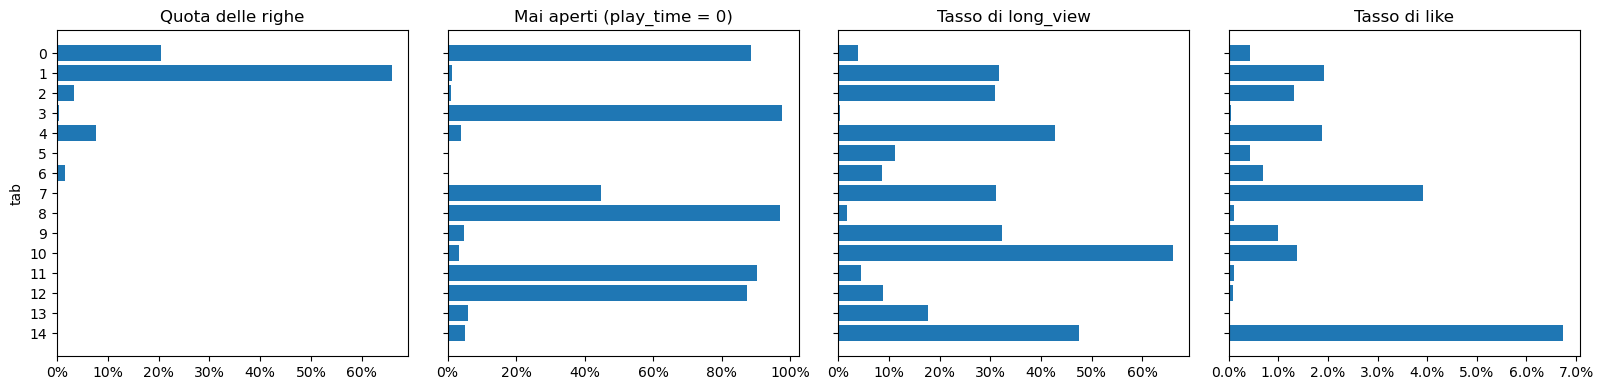

In [18]:
tab_stats = (df_log.assign(mai_aperto=df_log["play_time_ms"].eq(0))
             .groupby("tab")
             .agg(righe=("user_id", "size"),
                  mai_aperto=("mai_aperto", "mean"),
                  long_view=("long_view", "mean"),
                  like=("is_like", "mean")))
tab_stats["quota_righe"] = tab_stats["righe"] / tab_stats["righe"].sum()

cols = ["quota_righe", "mai_aperto", "long_view", "like"]
titles = ["Quota delle righe", "Mai aperti (play_time = 0)", "Tasso di long_view", "Tasso di like"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for ax, col, title in zip(axes, cols, titles):
    ax.barh(tab_stats.index.astype(str), tab_stats[col])
    ax.set_title(title)
    ax.xaxis.set_major_formatter(PercentFormatter(1))
axes[0].set_ylabel("tab")
axes[0].invert_yaxis()
plt.tight_layout()
plt.show()

Definire inanzitutto l'obiettivo finale.

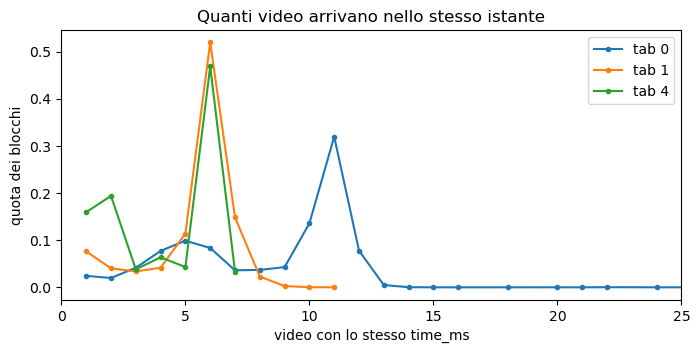

Righe che condividono il time_ms con altri video: 98.7%


In [19]:
batch = df_log.groupby(["tab", "user_id", "time_ms"]).size()

fig, ax = plt.subplots(figsize=(8, 3.5))
for t in [0, 1, 4]:
    dist = batch.loc[t].value_counts(normalize=True).sort_index()
    ax.plot(dist.index, dist.values, marker="o", ms=3, label=f"tab {t}")
ax.set(xlim=(0, 25), xlabel="video con lo stesso time_ms", ylabel="quota dei blocchi",
       title="Quanti video arrivano nello stesso istante")
ax.legend()
plt.show()

shared = df_log.groupby(["user_id", "time_ms"])["video_id"].transform("size") > 1
print(f"Righe che condividono il time_ms con altri video: {shared.mean():.1%}")

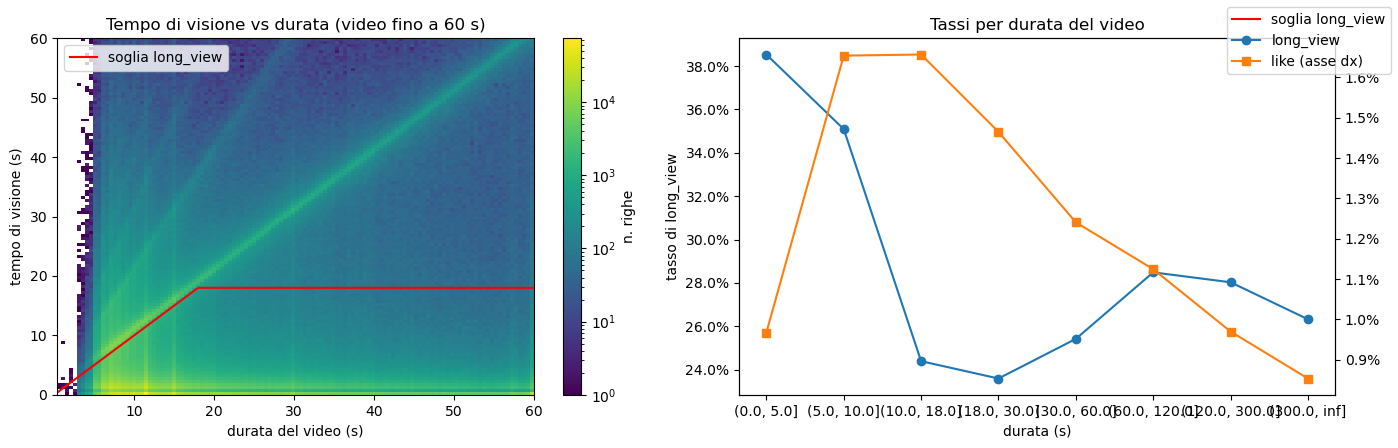

Righe con durata 0: 8.0%  ->  long_view 8.3%, like 4.3%  (resto: long_view 27.8%, like 1.3%)


In [20]:
short = df_log[df_log["duration_ms"].between(1, 60_000) & (df_log["play_time_ms"] <= 60_000)]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
h = axes[0].hist2d(short["duration_ms"] / 1000, short["play_time_ms"] / 1000,
                   bins=120, norm=LogNorm(), cmap="viridis")
fig.colorbar(h[3], ax=axes[0], label="n. righe")
x = np.linspace(0, 60, 300)
axes[0].plot(x, np.minimum(x, 18), color="red", lw=1.5, label="soglia long_view")
axes[0].set(xlabel="durata del video (s)", ylabel="tempo di visione (s)",
            title="Tempo di visione vs durata (video fino a 60 s)")
axes[0].legend(loc="upper left")

nz = df_log[df_log["duration_ms"] > 0]
bins = [0, 5, 10, 18, 30, 60, 120, 300, np.inf]
by_dur = nz.groupby(pd.cut(nz["duration_ms"] / 1000, bins), observed=True)[["long_view", "is_like"]].mean()
labels = by_dur.index.astype(str)
axes[1].plot(labels, by_dur["long_view"], marker="o", label="long_view")
axes[1].set(xlabel="durata (s)", ylabel="tasso di long_view", title="Tassi per durata del video")
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
ax_like = axes[1].twinx()
ax_like.plot(labels, by_dur["is_like"], marker="s", color="tab:orange", label="like (asse dx)")
ax_like.yaxis.set_major_formatter(PercentFormatter(1, decimals=1))
fig.legend(loc="upper right")
plt.tight_layout()
plt.show()

zero = df_log["duration_ms"] == 0
print(f"Righe con durata 0: {zero.mean():.1%}  ->  long_view {df_log.loc[zero, 'long_view'].mean():.1%}, "
      f"like {df_log.loc[zero, 'is_like'].mean():.1%}  (resto: long_view {nz['long_view'].mean():.1%}, like {nz['is_like'].mean():.1%})")
del short, nz

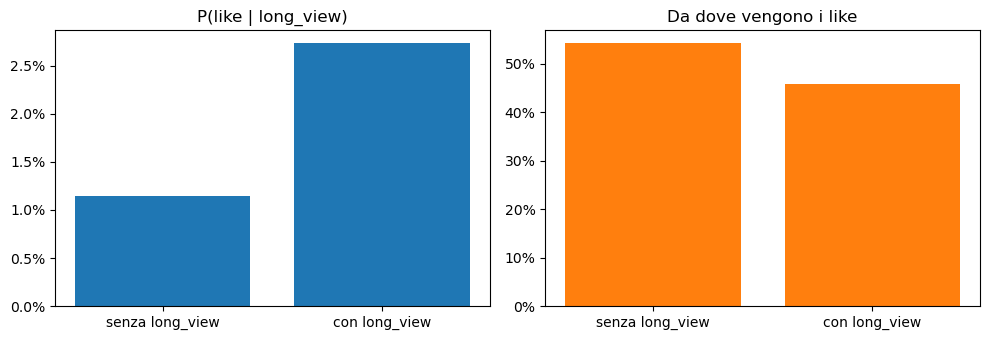

is_like,0,1
long_view,,
0,8544560,99024
1,2985643,83818


In [21]:
ct = pd.crosstab(df_log["long_view"], df_log["is_like"])
p_like = ct[1] / ct.sum(axis=1)
like_origin = ct[1] / ct[1].sum()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].bar(["senza long_view", "con long_view"], p_like.values)
axes[0].set_title("P(like | long_view)")
axes[0].yaxis.set_major_formatter(PercentFormatter(1, decimals=1))
axes[1].bar(["senza long_view", "con long_view"], like_origin.values, color="tab:orange")
axes[1].set_title("Da dove vengono i like")
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
plt.tight_layout()
plt.show()
display(ct)

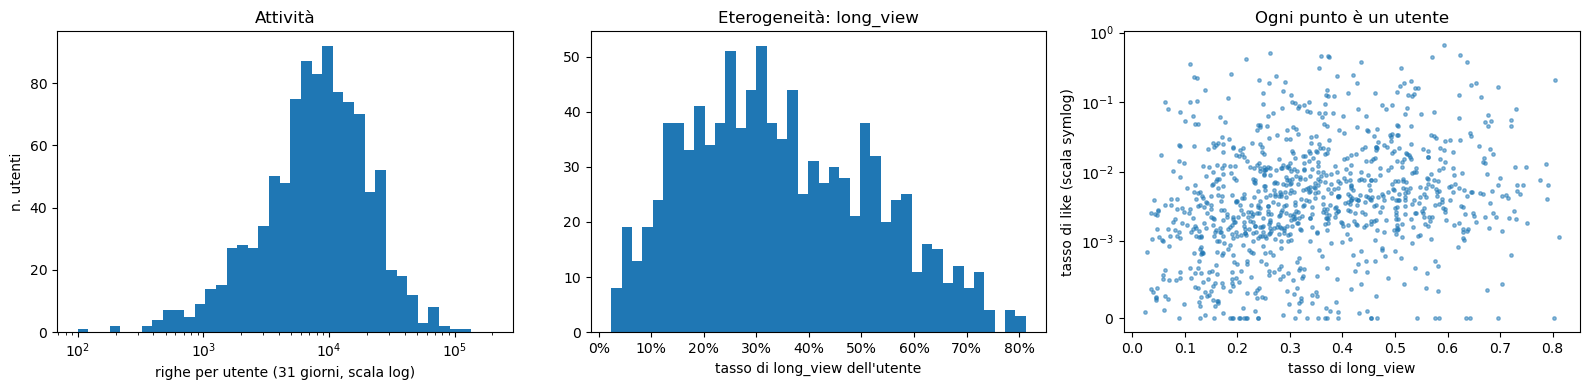

,righe,long_view,like
count,"1,000.00","1,000.00","1,000.00"
mean,"11,713.05",0.35,0.02
std,"11,935.07",0.17,0.06
min,116.00,0.02,0.00
5%,"1,228.80",0.09,0.00
50%,"8,327.50",0.33,0.00
95%,"33,606.00",0.66,0.10
max,"127,557.00",0.81,0.67


Correlazione tra i due tassi (per utente): 0.10


In [22]:
per_user = df_log.groupby("user_id").agg(righe=("video_id", "size"),
                                         long_view=("long_view", "mean"),
                                         like=("is_like", "mean"))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(per_user["righe"], bins=np.logspace(2, 5.3, 40))
axes[0].set(xscale="log", xlabel="righe per utente (31 giorni, scala log)", ylabel="n. utenti", title="Attività")
axes[1].hist(per_user["long_view"], bins=40)
axes[1].set(xlabel="tasso di long_view dell'utente", title="Eterogeneità: long_view")
axes[1].xaxis.set_major_formatter(PercentFormatter(1))
axes[2].scatter(per_user["long_view"], per_user["like"], s=6, alpha=0.5)
axes[2].set_yscale("symlog", linthresh=1e-3)
axes[2].set(xlabel="tasso di long_view", ylabel="tasso di like (scala symlog)", title="Ogni punto è un utente")
plt.tight_layout()
plt.show()

display(per_user.describe(percentiles=[0.05, 0.5, 0.95]))
print(f"Correlazione tra i due tassi (per utente): {per_user['long_view'].corr(per_user['like']):.2f}")

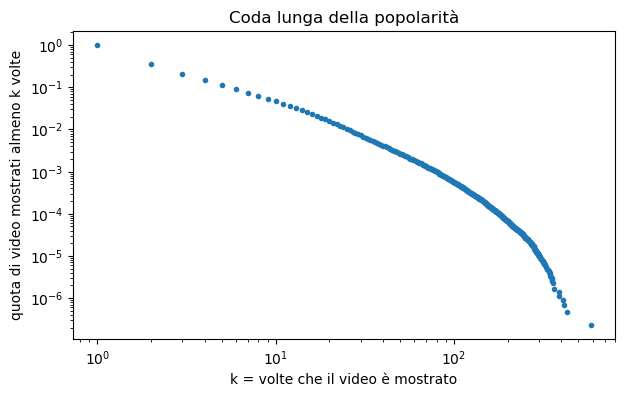

Video distinti: 4,369,953
Mostrati 1 volta: 65.0%   meno di 5 volte: 88.8%
L'1% dei video più mostrati copre il 17.4% delle righe


In [23]:
per_video = df_log.groupby("video_id").size()
freq = per_video.value_counts().sort_index()
ccdf = freq[::-1].cumsum()[::-1] / len(per_video)

fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog(ccdf.index, ccdf.values, marker=".", ls="none")
ax.set(xlabel="k = volte che il video è mostrato", ylabel="quota di video mostrati almeno k volte",
       title="Coda lunga della popolarità")
plt.show()

print(f"Video distinti: {len(per_video):,}")
print(f"Mostrati 1 volta: {(per_video == 1).mean():.1%}   meno di 5 volte: {(per_video < 5).mean():.1%}")
top = per_video.nlargest(len(per_video) // 100).sum() / per_video.sum()
print(f"L'1% dei video più mostrati copre il {top:.1%} delle righe")

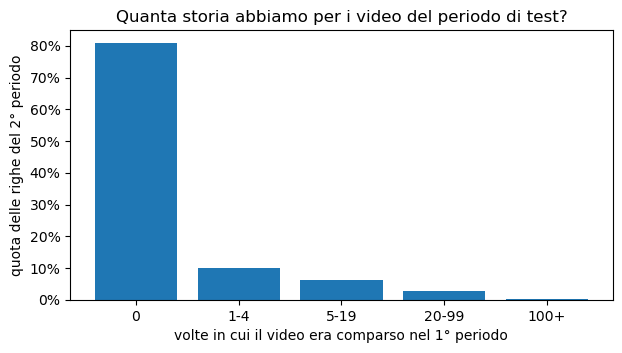

video_id
0       0.81
1-4     0.10
5-19    0.06
20-99   0.03
100+    0.00
Name: proportion, dtype: float64

In [24]:
period1 = df_log["date"] <= 20220421
cnt1 = df_log.loc[period1].groupby("video_id").size()
hist_n = df_log.loc[~period1, "video_id"].map(cnt1).fillna(0)

bins = [-1, 0, 4, 19, 99, np.inf]
lbl = ["0", "1-4", "5-19", "20-99", "100+"]
share = pd.cut(hist_n, bins, labels=lbl).value_counts(normalize=True).reindex(lbl)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(share.index, share.values)
ax.set(xlabel="volte in cui il video era comparso nel 1° periodo", ylabel="quota delle righe del 2° periodo",
       title="Quanta storia abbiamo per i video del periodo di test?")
ax.yaxis.set_major_formatter(PercentFormatter(1))
plt.show()
display(share)

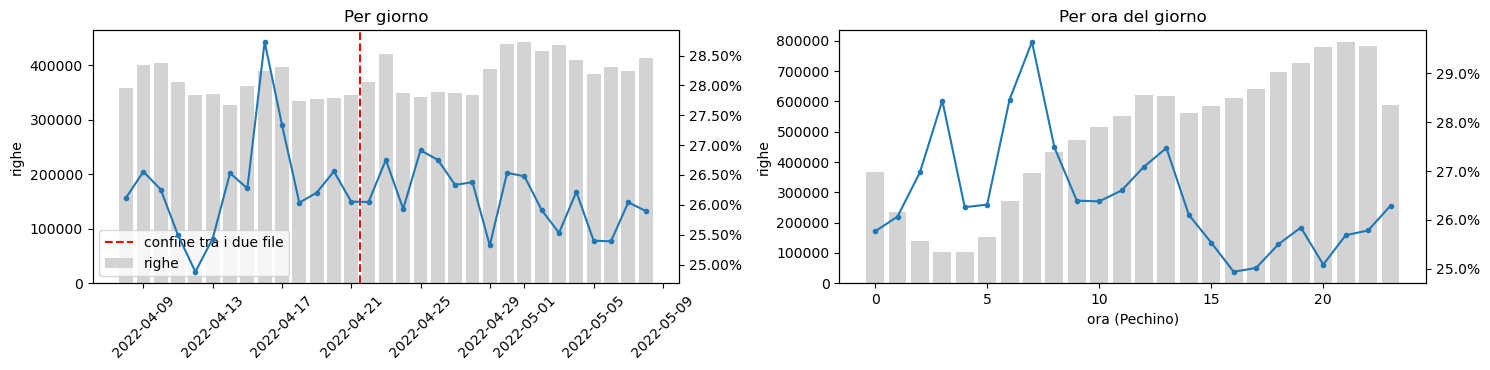

In [25]:
daily = df_log.groupby("date").agg(righe=("user_id", "size"),
                                   long_view=("long_view", "mean"),
                                   like=("is_like", "mean"))
daily.index = pd.to_datetime(daily.index.astype(str), format="%Y%m%d")
hourly = df_log.groupby(df_log["hourmin"] // 100).agg(righe=("user_id", "size"),
                                                      long_view=("long_view", "mean"))

fig, axes = plt.subplots(1, 2, figsize=(15, 3.8))
axes[0].bar(daily.index, daily["righe"], color="lightgray", label="righe")
axes[0].axvline(pd.Timestamp("2022-04-21 12:00"), color="red", ls="--", label="confine tra i due file")
axes[0].set(ylabel="righe", title="Per giorno")
ax_r = axes[0].twinx()
ax_r.plot(daily.index, daily["long_view"], color="tab:blue", marker="o", ms=3, label="long_view")
ax_r.yaxis.set_major_formatter(PercentFormatter(1))
axes[0].legend(loc="lower left")
axes[0].tick_params(axis="x", rotation=45)

axes[1].bar(hourly.index, hourly["righe"], color="lightgray")
axes[1].set(xlabel="ora (Pechino)", ylabel="righe", title="Per ora del giorno")
ax_r2 = axes[1].twinx()
ax_r2.plot(hourly.index, hourly["long_view"], color="tab:blue", marker="o", ms=3)
ax_r2.yaxis.set_major_formatter(PercentFormatter(1))
plt.tight_layout()
plt.show()

### Cosa abbiamo imparato dai log standard
- **Due interfacce, due problemi.** Tab 1/2/4 si comportano come il feed a colonna singola (blocchi da ~6 video, quasi tutti avviati); tab 0/3/8/11/12 come la griglia (blocchi da ~11, >85% mai aperti). Per la domanda sul feed il perimetro è il tab 1 (eventualmente 1+2+4): nella griglia `long_view=0` significa "mai cliccato".
- **`time_ms` è l'istante della richiesta**, condiviso dal 98,7% delle righe: le feature sequenziali vanno costruite solo su blocchi precedenti.
- **`long_view` è una regola deterministica su `play_time_ms` e `duration_ms`**: `play_time_ms` non può essere una feature; l'effetto della durata è in parte meccanico (soglia a 18 s).
- **Like e long_view divergono**: anche escludendo i video a durata 0 e restando nel tab 1, il 46% dei like arriva senza visione lunga → il trade-off del project work è reale.
- **Utenti molto eterogenei** (long_view dal 2% all'81%; correlazione tra i due tassi 0,10) → margine per la personalizzazione; metriche da calcolare per utente.
- **Popolarità per video quasi assente**: l'81% delle righe del 2° periodo riguarda video mai visti nel 1° → la baseline di popolarità va definita a livello più aggregato o su un sottoinsieme di video.
- **Nessuna deriva temporale** nei tassi: lo split train/test per data è sensato.
- **Da sistemare**: 101.220 righe duplicate (90% nel tab 6) e l'8% di righe con `duration_ms = 0` (like al 4,3%, long_view poco significativo: forse post fotografici, da verificare con `video_features_basic`).

Cosa intendo per "richiesta" e "6 video"

Un'app di short video non scarica un video alla volta. Quando stai per finire quelli già caricati, l'app chiede al server un nuovo blocco di video e il server li manda tutti insieme. Nel log tutti i video di quel blocco hanno lo stesso time_ms: è l'istante in cui è arrivato il blocco, non quello in cui hai guardato ciascun video.

Per misurare quanti video arrivano in ogni blocco, il grafico raggruppa le righe per (user_id, time_ms) e conta quante righe ha ogni gruppo. È quello che fa df_log.groupby(["tab", "user_id", "time_ms"]).size(). Poi guarda quali dimensioni sono più frequenti:

Tab 1 e 4: il picco è a 6, cioè circa metà dei blocchi contiene esattamente 6 video. Ha senso per un feed a schermo intero: l'app carica i prossimi 6 video da far scorrere uno alla volta.
Tab 0: il picco è tra 10 e 12. Ha senso per una griglia: una schermata a due colonne mostra molte miniature insieme, quindi ne serve un blocco più grande per riempirla.